# 11 · What-if rescheduling (Step 8)

At 20:00 on D−1 the desk sees the day-D risk of every flight. For the **daily top 10%** of the whole timetable (the primary policy; flights later cancelled or diverted are included, since that is unknown at 20:00) it tries moving the scheduled departure by whole hours on the same day and keeps a move only if the model's **predicted** number of delayed flights at that origin on D falls by at least δ, counting the effect on every other flight at that origin (congestion spill-over).

**Explicit assumptions.**

* **A1, predictive not causal.** The model's association between hour / congestion and delay is read as the effect of a move. Weather and ATC programmes are unknown at 20:00 D−1.
* **A2, scope of a move.** Same day, whole hours, block time unchanged; carrier, aircraft, route and flight number unchanged; rotations, crews and connections not modelled.
* **A3, capacity.** No origin-hour busier than that origin's busiest training hour; new hours within its observed departure hours.
* **A4, cost.** Each move costs 0.02 expected delayed flights; the window (1–2 h) and δ are chosen on **Sep–Oct** by net predicted benefit and frozen for Nov–Dec.

**Leakage.** A move edits only schedule-derived inputs and the moved flight's origin-hour history, read from a table built with the Phase 1 decision clock; tests show that scrambling every outcome from day D on leaves day D's plan unchanged (`tests/test_reschedule.py`).

In [1]:
import sys, json, pathlib
ROOT = pathlib.Path.cwd().resolve().parent
for p in (ROOT / 'src', ROOT.parent / 'phase1' / 'src'):
    sys.path.insert(0, str(p))

import aerocast_dl  # torch before XGBoost (OpenMP)
import numpy as np, pandas as pd
from IPython.display import Image, display
from aerocast_dl import config, pipeline
R, F = config.RESULTS_DIR, config.FIGURES_DIR
pd.set_option('display.precision', 4)


## 1. Rule chosen on Sep–Oct

In [2]:
sel = json.loads((R / 'selection.json').read_text())
print('model:', sel['reschedule']['model'], '| frozen rule:', sel['reschedule']['params'], '| move cost:', sel['reschedule']['move_cost'])
pd.read_csv(R / 'reschedule_tuning.csv')

model: logreg | frozen rule: {'window': 2, 'delta': 0.02} | move cost: 0.02


,window,delta,moves,moves_per_day,share_of_candidates_moved,predicted_delays_avoided,predicted_delays_avoided_per_day,avoided_per_move,net_benefit,share_moved_earlier,spillover_share
0,1,0.01,2912,47.7377,0.5129,74.7089,1.2247,0.0257,16.4689,0.5264,0.3431
1,1,0.02,1607,26.3443,0.2830,55.0646,0.9027,0.0343,22.9246,0.4717,0.3352
2,1,0.05,204,3.3443,0.0359,12.7133,0.2084,0.0623,8.6333,0.4706,0.2926
3,2,0.01,3613,59.2295,0.6363,125.9255,2.0644,0.0349,53.6655,0.5704,0.3260
4,2,0.02,2643,43.3279,0.4655,111.8272,1.8332,0.0423,58.9672,0.5986,0.3213
5,2,0.05,762,12.4918,0.1342,51.8240,0.8496,0.0680,36.5840,0.6430,0.3212


## 2. Applied to Nov–Dec, with cost sensitivity and a naive comparison

The naive rule moves every candidate one hour earlier whenever capacity allows. Comparing both shows whether the model's per-flight assessment adds anything beyond 'earlier is better'.

In [3]:
pd.read_csv(R / 'reschedule_test.csv')

,rule,cost,window,delta,moves,moves_per_day,share_of_candidates_moved,predicted_delays_avoided,predicted_delays_avoided_per_day,avoided_per_move,net_benefit,share_moved_earlier,spillover_share
0,frozen (Sep-Oct),0.00,2,0.02,2993,49.0656,0.5375,117.2699,1.9225,0.0392,117.2699,0.5272,0.2890
1,frozen (Sep-Oct),0.02,2,0.02,2993,49.0656,0.5375,117.2699,1.9225,0.0392,57.4099,0.5272,0.2890
2,frozen (Sep-Oct),0.05,2,0.02,2993,49.0656,0.5375,117.2699,1.9225,0.0392,-32.3801,0.5272,0.2890
3,naive: every candidate 1 h earlier,0.00,1,NaN,5545,90.9016,0.9959,7.9690,0.1306,0.0014,7.9690,1.0000,-3.5904
4,naive: every candidate 1 h earlier,0.02,1,NaN,5545,90.9016,0.9959,7.9690,0.1306,0.0014,-102.9310,1.0000,-3.5904
5,naive: every candidate 1 h earlier,0.05,1,NaN,5545,90.9016,0.9959,7.9690,0.1306,0.0014,-269.2810,1.0000,-3.5904


In [4]:
mv = pd.read_csv(R / 'reschedule_test_moves.csv')
print(f"{len(mv)} moves; mean risk of moved flights {mv['risk_before'].mean():.3f} -> {mv['risk_after'].mean():.3f}; spill-over share {mv['spillover'].sum() / mv['net_gain'].sum():.2f}")
mv.groupby(['origin', 'shift']).size().unstack(fill_value=0)

2993 moves; mean risk of moved flights 0.409 -> 0.381; spill-over share 0.29


shift,-2,-1,1,2
origin,,,,
EWR,402,48,95,574
JFK,255,44,65,301
LGA,781,48,35,345


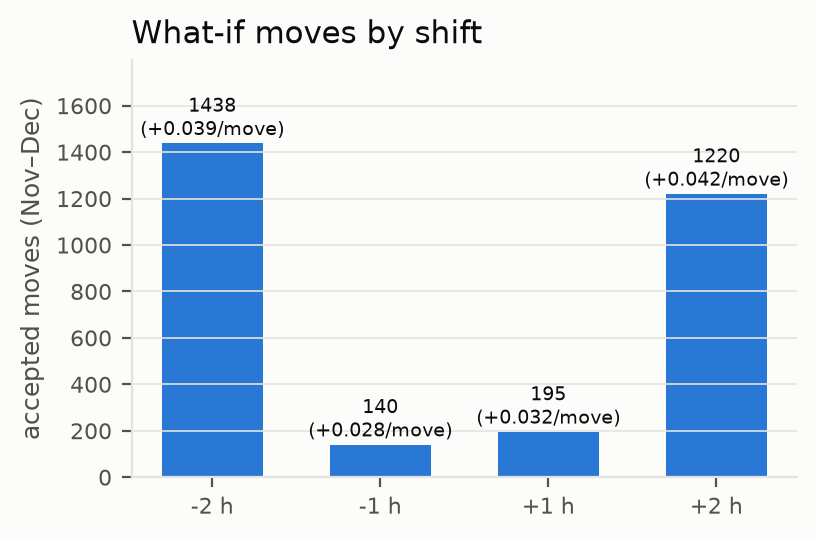

In [5]:
display(Image(F / 'reschedule_shifts.png', width=420))

## 3. How to read this

The numbers are **predicted** delays avoided under A1–A4, not realised savings: the data hold no counterfactual outcomes, no costs and no rotations. The analysis answers a narrower question: *given this model, which re-timings would a capacity-limited desk consider, and how much predicted risk would they remove?*